# Page: three ways to compose a scene instance

All three store the per-instance difference in the **parent** scene (the map), never in the base `.tscn`. They differ in what you are allowed to change and what it costs.

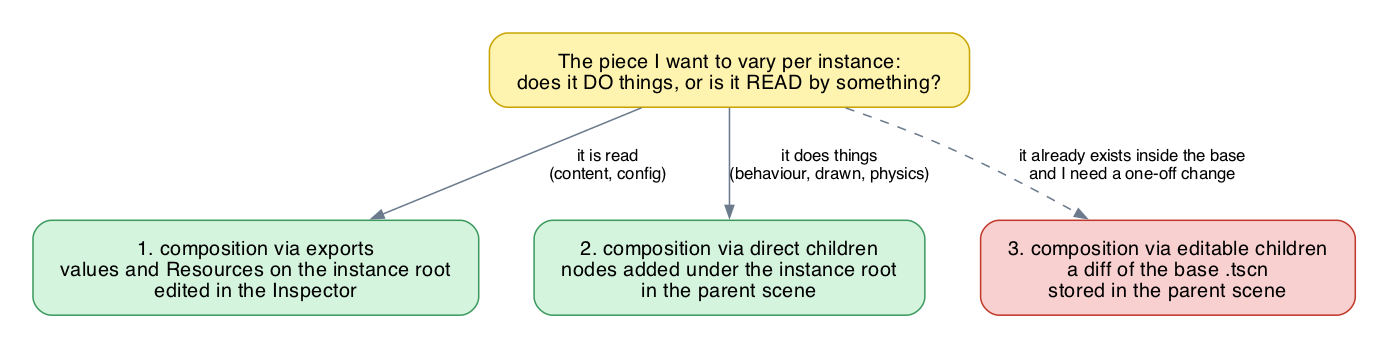

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  rankdir=TB;
  node [shape=box, style="rounded,filled", fillcolor="#f4f4f4", fontname="Helvetica"];
  edge [fontname="Helvetica", fontsize=11];
  ask      [label="The piece I want to vary per instance:\ndoes it DO things, or is it READ by something?", fillcolor="#fff3b0", color="#c9a400"];
  exports  [label="1. composition via exports\nvalues and Resources on the instance root\nedited in the Inspector", fillcolor="#d4f4dd", color="#3c9a5f"];
  children [label="2. composition via direct children\nnodes added under the instance root\nin the parent scene", fillcolor="#d4f4dd", color="#3c9a5f"];
  editable [label="3. composition via editable children\na diff of the base .tscn\nstored in the parent scene", fillcolor="#f9d0d0", color="#c0392b"];
  ask -> exports  [label="it is read\n(content, config)"];
  ask -> children [label="it does things\n(behaviour, drawn, physics)"];
  ask -> editable [label="it already exists inside the base\nand I need a one-off change", style=dashed];
}
```

</details>

| | 1. Composition via exports | 2. Composition via direct children | 3. Composition via editable children (diffed base `.tscn`) |
|---|---|---|---|
| What it is | `@export` values and Resources on the instance root | nodes you add under the instance root in the parent scene | ticking Editable Children and changing nodes that live inside the base |
| **Pros** | scene tree stays clean | no code needed, works today | change anything, no code and no new export |
| | the base decides what may vary, so instances cannot break it | each child gets `_process`, signals, `get_parent()`, `get_tree()` for free | fastest way to try a one-off tweak |
| | Resources can be saved as files and reused or shared | visible, selectable and draggable in the editor | |
| | survives renames and restructuring inside the base | independent of the base's internals | |
| **Limitations** | needs code: the base must declare each export | every child shows in the parent's tree, so big maps get cluttered | overrides are tied to node paths: rename or move a node in the base and they are silently lost |
| | a Resource has no `get_owner()` or tree access, the owner must be passed in | cannot change nodes that are inside the base | exposes the whole subtree in the parent's tree |
| | the holder must forward `_process`, `_input` and so on to Resources that need them | the base must be written to find and use children it did not create | bypasses the base's interface, so the base cannot protect itself |
| | Resources are shared by default; runtime state needs Local To Scene or a duplicate | repeated setups are copy-pasted per instance unless made an inherited scene | hard to see later what was overridden and why |
| **When to use** | the piece is content or configuration: stats, text, a command list | the piece is behaviour: runs every frame, is drawn, collides, emits signals | a genuine one-off on a single instance |
| | you want many instances with a clean tree | it is a reusable capability bolted on: hitbox, health, interactable | prototyping, before deciding what deserves an export |
| | variation should be limited to what the base allows | the piece is unique to this one placement | third-party scenes you cannot or should not edit |
| **Godot's view** | the intended interface of a scene | equally native, the component pattern | escape hatch |
| **For RPGM maps** | **target for event scripts (as a command list)** | **what works today for `_RPGM_Script` nodes** | **avoid as an authoring workflow** |

- **Not a capability line, a cost line.** A Resource can do anything a child node does if its holder forwards the calls; a child node is the cheaper choice whenever that forwarding list gets long.
- **A variant placed many times** is a fourth tool that pairs with any of the three: New Inherited Scene gives the variant its own `.tscn`, so the map shows one node.
- **Closest thing to `get_owner()` on a Resource:** `get_local_scene()`, which returns the scene root and only when Local To Scene is ticked. Passing the owner into each call (`rpgm_command.run(self)`) is simpler and keeps the Resource stateless.

Not run in the editor: this is from how Godot instancing and Resources work, not from a test in this project. Earlier page with the old numbering: `instance-composition-paradigms.ipynb`.
